# Logical magic states with IBM Aachen noise

This notebook runs the existing B0, B1, B2_ED, and five-qubit B2_BK circuits with
the **packaged IBM Aachen calibration snapshot**. All computation is local in
Aer. There are **no manually inserted Pauli faults** in this experiment.

The circuits are routed onto a fixed connected patch, compiled to Aachen's native
gates, and scheduled. The model includes gate errors, syndrome readout error,
and **T1/T2 relaxation during every explicit delay**, including the data-qubit
wait while syndrome readout finishes. Use the **Python (quantum-jax)** kernel.
The ideal and manual-fault experiments remain in `01_ideal_magic_states.ipynb`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import display, Markdown, Image
from qiskit import qpy

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'logical_magic').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'logical_magic').exists()
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from logical_magic import CODES, build_preparation
from logical_magic.aachen_noise import (
    AachenPatch, ScheduledPreparation, simulate_scheduled, validate_idle_relaxation,
)
from run_noisy import run_experiment, summary_table

OUTPUT = ROOT / 'results' / 'noisy_aachen'
SHOTS = 8192
SEED = 20261014
backend = AachenPatch()
provenance = backend.provenance()
print('Python:', sys.executable)
print('Calibration:', provenance['calibration_date'])
print('Physical qubits in local wire order:', provenance['physical_patch'])
print('dt:', provenance['dt_seconds'], 'seconds')

Python: /Users/runzhemo/anaconda3/envs/quantum-jax/bin/python
Calibration: 2026-04-17T12:29:46+02:00
Physical qubits in local wire order: [3, 2, 4, 16, 1, 5, 23, 0, 6]
dt: 4e-09 seconds


## 1. Calibration and assumptions

`FakeAachen` supplies the local snapshot; it is not a current online calibration.
The patch is a fixed breadth-first neighborhood rooted at physical qubit 3,
without noise-aware placement optimization. Initial placement uses the listed
wire order. Routing may change which physical wires carry data and syndrome.

The reduced backend preserves the snapshot's native connectivity, instruction
errors/durations, and qubit T1/T2 values. Aer uses its standard BackendV2 model:
calibrated depolarizing plus gate-duration relaxation, independent symmetric
readout assignment from the Target's average readout errors, and delay relaxation
at zero temperature. The readout error is especially high on physical qubit 2;
check the final routed placement before interpreting its effect.

The initial state is ideal all-zero. There is no additional reset, crosstalk,
leakage, drift, or correlated-noise model. No installed package is changed.

In [2]:
table = ['| Local wire | IBM qubit | T1 (µs) | T2 used (µs) | Readout error | Measurement (µs) |',
         '|---:|---:|---:|---:|---:|---:|']
for q in provenance['qubits']:
    table.append(f"| {q['local']} | {q['physical']} | {q['t1_seconds']*1e6:.2f} | {q['effective_t2_seconds']*1e6:.2f} | {q['readout_error']:.5f} | {q['readout_duration_seconds']*1e6:.3f} |")
display(Markdown('\n'.join(table)))

| Local wire | IBM qubit | T1 (µs) | T2 used (µs) | Readout error | Measurement (µs) |
|---:|---:|---:|---:|---:|---:|
| 0 | 3 | 230.99 | 252.99 | 0.00317 | 2.584 |
| 1 | 2 | 178.13 | 172.85 | 0.08667 | 2.584 |
| 2 | 4 | 212.90 | 271.51 | 0.00696 | 2.584 |
| 3 | 16 | 219.37 | 431.95 | 0.00330 | 2.584 |
| 4 | 1 | 273.99 | 279.46 | 0.00354 | 2.584 |
| 5 | 5 | 184.41 | 194.10 | 0.00256 | 2.584 |
| 6 | 23 | 270.63 | 274.04 | 0.00293 | 2.584 |
| 7 | 0 | 256.36 | 399.53 | 0.00769 | 2.584 |
| 8 | 6 | 148.34 | 138.48 | 0.00769 | 2.584 |

## 2. Verify that delay relaxation is actually active

`NoiseModel.from_backend(..., thermal_relaxation=True)` in Aer 0.17.2 already
adds a Delay-only `RelaxationNoisePass`. We do **not** add another pass.
Scheduling creates the delays on which this pass acts.

As a unit check, prepare clean simulator states |1〉 and |+〉, then apply only a
50 µs delay on the patch's first qubit. The expected excited population and X
coherence are $e^{-t/T_1}$ and $e^{-t/T_2}$. This checks time units and detects a
missing or duplicated relaxation channel; it is not a fault-insertion experiment.

In [3]:
idle_check = validate_idle_relaxation(backend)
display(idle_check)
assert idle_check['max_absolute_error'] < 1e-12

{'physical_qubit': 3,
 'delay_seconds': 5e-05,
 'observed_excited_population_and_x': [0.8053644411108674, 0.8206708558377012],
 'expected_exp_minus_t_over_t1_t2': [0.8053644411108675, 0.8206708558377015],
 'max_absolute_error': 3.3306690738754696e-16}

## 3. Run the scheduled circuits with the Aachen model

Three modes use the same routed native circuit:

1. **Ideal control:** all noise disabled.
2. **No-delay ablation:** calibrated gate/readout noise, including gate-duration
   relaxation; only Delay instructions are omitted from channel evolution.
3. **Full:** gate/readout noise plus relaxation during all scheduled delays.

ALAP scheduling and a terminal barrier align syndrome readout. In B2 the output
is delivered at readout completion, so every data qubit waits **2.584 µs** during
syndrome readout, in addition to earlier idles. The standard Aer measurement
model applies assignment error on measured ancillas; it adds no separate
measurement-duration relaxation channel on those ancillas. Data remain unmeasured.

For true ancilla blocks $\rho_s$, the actual accepted output is

$$p_{\rm acc}=\sum_s P(\text{recorded }0\mid s)\operatorname{Tr}\rho_s,\qquad
\rho_{\rm acc}=\frac{\sum_s P(\text{recorded }0\mid s)\rho_s}{p_{\rm acc}}.$$

No active recovery or extra codespace postselection is performed. Fidelity is
$\langle\psi_{\rm target}|\rho_{\rm acc}|\psi_{\rm target}\rangle$ from exact
noisy density-matrix evolution. This section uses simulator diagnostics;
Sections 7–8 below add readout ablation and finite-shot fidelity measurements.
8,192 Aer shots per mode provide an independent sampled syndrome distribution.

The following cell displays the saved run. Set `RERUN=True` to rerun the
experiment and update `results/noisy_aachen`.

In [4]:
RERUN = False
if RERUN or not (OUTPUT / 'noisy_results.json').exists():
    report = run_experiment(OUTPUT, shots=SHOTS, seed=SEED)
else:
    report = json.loads((OUTPUT / 'noisy_results.json').read_text())

for row in report['rows']:
    assert np.isclose(row['ideal']['fidelity'], 1)
    assert np.isclose(row['ideal']['acceptance'], 1/6 if row['strategy'] == 'B2_BK' else 1)
display(Markdown(summary_table(report)))

| Code / strategy | Acceptance | Fidelity incl. delay | Fidelity omitting delay | Codespace population | Duration (µs) | CZ gates |
|---|---:|---:|---:|---:|---:|---:|
| four/B0 | 1.000000 | 0.999792 | 0.999792 | 1.000000 | 0.064 | 0 |
| four/B1 | 1.000000 | 0.985589 | 0.987774 | 0.987178 | 0.668 | 7 |
| four/B2_ED | 0.905051 | 0.943088 | 0.980060 | 0.945341 | 5.424 | 39 |
| five/B0 | 1.000000 | 0.999784 | 0.999784 | 1.000000 | 0.064 | 0 |
| five/B1 | 1.000000 | 0.908950 | 0.926142 | 0.913418 | 3.164 | 33 |
| five/B2_ED | 0.744221 | 0.886818 | 0.948951 | 0.894925 | 10.396 | 106 |
| five/B2_BK | 0.147074 | 0.854524 | 0.913466 | 0.856809 | 6.224 | 67 |

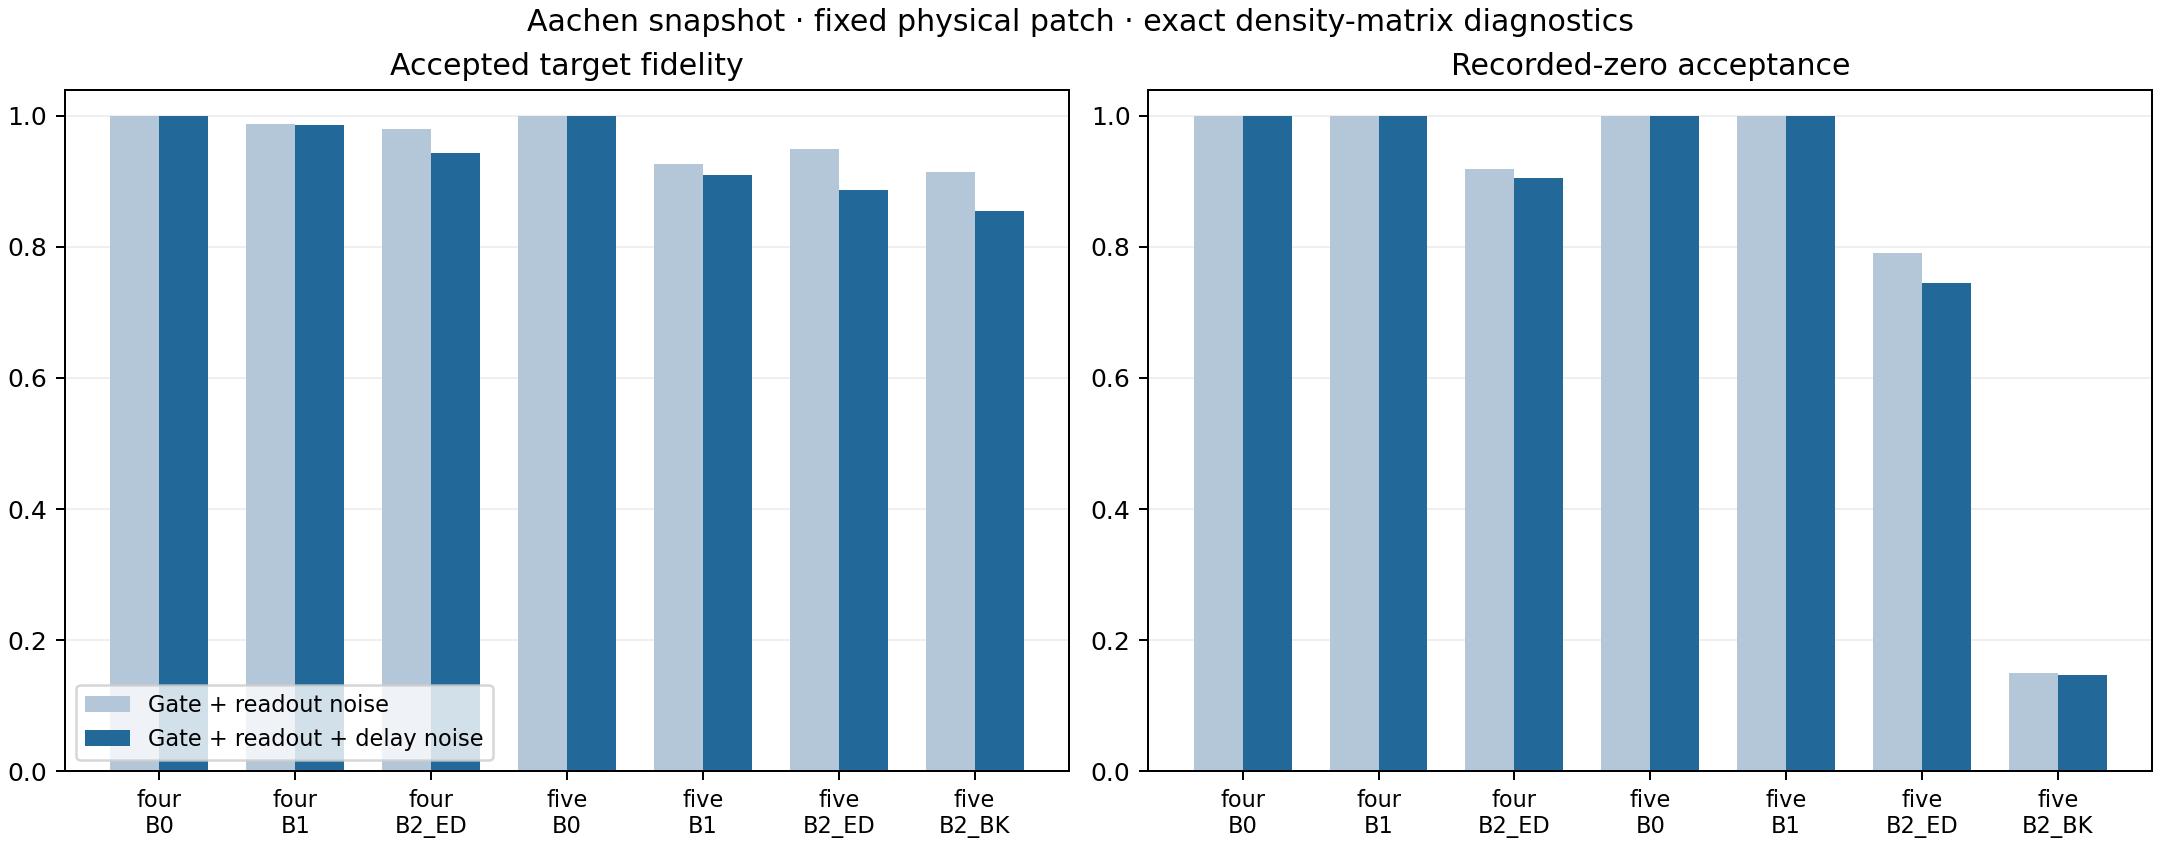

In [5]:
display(Image(filename=str(OUTPUT / 'noisy_comparison.png')))

## 4. Separate loss from logical distortion

A recorded zero syndrome does not guarantee the final state is in the
codespace. Check faults and late relaxation, especially during readout, can
leave accepted data outside it. Codespace population and within-codespace
logical fidelity below are **diagnostics**. The reported main fidelity includes
both codespace loss and logical distortion; no simulator-only filter improves
the delivered output.

B0/B1 accept every shot. B2_ED rejects recorded nonzero syndromes. B2_BK has
ideal acceptance 1/6 even without errors. All rows use each strategy's own
completion time; B0/B1 have no syndrome-readout wait. A shared downstream use
time would require additional storage waits for the faster preparations.

In [6]:
table = ['| Code / strategy | Full fidelity | Codespace population | Logical fidelity within codespace | Accepted fraction with nonzero true syndrome |',
         '|---|---:|---:|---:|---:|']
for row in report['rows']:
    r = row['full']
    table.append(f"| {row['code']}/{row['strategy']} | {r['fidelity']:.6f} | {r['codespace_population']:.6f} | {r['fidelity_conditioned_on_codespace_diagnostic']:.6f} | {r['accepted_fraction_from_nonzero_true_syndrome']:.6f} |")
display(Markdown('\n'.join(table)))
for row in report['rows']:
    if row['strategy'].startswith('B2'):
        delta = row['no_delay']['fidelity'] - row['full']['fidelity']
        print(f"{row['code']}/{row['strategy']}: omitting delays overstates fidelity by {100*delta:.2f} percentage points")

| Code / strategy | Full fidelity | Codespace population | Logical fidelity within codespace | Accepted fraction with nonzero true syndrome |
|---|---:|---:|---:|---:|
| four/B0 | 0.999792 | 1.000000 | 0.999792 | 0.000000 |
| four/B1 | 0.985589 | 0.987178 | 0.998391 | 0.000000 |
| four/B2_ED | 0.943088 | 0.945341 | 0.997616 | 0.000309 |
| five/B0 | 0.999784 | 1.000000 | 0.999784 | 0.000000 |
| five/B1 | 0.908950 | 0.913418 | 0.995109 | 0.000000 |
| five/B2_ED | 0.886818 | 0.894925 | 0.990941 | 0.000627 |
| five/B2_BK | 0.854524 | 0.856809 | 0.997334 | 0.006781 |

four/B2_ED: omitting delays overstates fidelity by 3.70 percentage points
five/B2_ED: omitting delays overstates fidelity by 6.21 percentage points
five/B2_BK: omitting delays overstates fidelity by 5.89 percentage points


## 5. Recorded syndrome counts and uncertainty

These Wilson intervals apply to the finite-shot acceptance estimate. The exact
model fidelities and probabilities above have no sampling error; model mismatch
with a physical device is a separate limitation. Bitstrings are s[m−1]…s[0].

In [7]:
table = ['| Code / strategy | Exact acceptance | Sampled acceptance | Wilson 95% interval |',
         '|---|---:|---:|---|']
for row in report['rows']:
    r = row['full']
    lo, hi = r['acceptance_wilson_95_interval']
    table.append(f"| {row['code']}/{row['strategy']} | {r['acceptance']:.6f} | {r['acceptance_sampled']:.6f} | [{lo:.6f}, {hi:.6f}] |")
display(Markdown('\n'.join(table)))
selected = next(r for r in report['rows'] if r['code'] == 'four' and r['strategy'] == 'B2_ED')
print('four/B2_ED raw recorded counts:', selected['full']['syndrome_counts'])

| Code / strategy | Exact acceptance | Sampled acceptance | Wilson 95% interval |
|---|---:|---:|---|
| four/B0 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| four/B1 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| four/B2_ED | 0.905051 | 0.899048 | [0.892336, 0.905386] |
| five/B0 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| five/B1 | 1.000000 | 1.000000 | [0.999531, 1.000000] |
| five/B2_ED | 0.744221 | 0.740112 | [0.730504, 0.749495] |
| five/B2_BK | 0.147074 | 0.151489 | [0.143889, 0.159416] |

four/B2_ED raw recorded counts: {'110': 13, '001': 205, '100': 157, '101': 82, '000': 7365, '010': 260, '111': 14, '011': 96}


## 6. Inspect and replay the saved schedule

The QPY files preserve the exact native circuits used for these results.
Re-synthesizing a Clifford circuit in another process/version may change gate
ordering and routing. The replay below uses the saved circuit, physical mapping,
and seed. Calibration file hashes are checked against the current local snapshot.
The original measured circuit is saved; simulator snapshots are added only for
analysis. The saved state is reordered into logical data order, with spectator
wires traced out.

In [8]:
for name, info in report['backend']['snapshot_files'].items():
    assert info['sha256'] == provenance['snapshot_files'][name]['sha256']
res = selected['resources']
print('Data physical qubits at delivery:', res['final_data_physical_qubits'])
print('Syndrome physical qubits in bit order:', res['syndrome_physical_qubits_in_bit_order'])
print('Total duration (µs):', res['duration_seconds']*1e6)
print('Data wait during syndrome readout (µs):', res['syndrome_readout_wait_seconds']*1e6)
print('Idle time by local physical wire (µs):', np.array(res['idle_seconds_by_local_wire'])*1e6)
with (OUTPUT / 'circuits' / 'four_B2_ED.qpy').open('rb') as f:
    saved_circuit = qpy.load(f)[0]
replay = ScheduledPreparation(
    build_preparation(CODES['four'], 'B2_ED'), saved_circuit,
    tuple(res['final_data_local_wires']), tuple(res['syndrome_local_wires_in_bit_order']), res,
)
replayed, accepted_rho = simulate_scheduled(replay, backend, mode='full', shots=SHOTS, seed=SEED)
assert np.isclose(replayed['fidelity'], selected['full']['fidelity'])
assert np.isclose(replayed['acceptance'], selected['full']['acceptance'])
assert replayed['syndrome_counts'] == selected['full']['syndrome_counts']
print('Saved-circuit replay agrees, including seeded counts.')
print(saved_circuit.draw(output='text', fold=120))

Data physical qubits at delivery: [5, 3, 2, 16]
Syndrome physical qubits in bit order: [1, 4, 23]
Total duration (µs): 5.424
Data wait during syndrome readout (µs): 2.584
Idle time by local physical wire (µs): [2.952 3.552 1.872 4.588 2.14  5.024 2.64  5.424 5.424]


Saved-circuit replay agrees, including seeded counts.
global phase: 7π/4
                ┌────────┐       ┌────┐  ┌──────────┐   ┌────┐           ┌────┐         ┌────┐   ┌────┐   »
   q_0 -> 0 ────┤ Rz(-π) ├───────┤ √X ├──┤ Rz(3π/4) ├───┤ √X ├───■───────┤ √X ├───────■─┤ √X ├─■─┤ √X ├─■─»
             ┌──┴────────┴──┐ ┌──┴────┴─┐└──┬────┬──┘┌──┴────┴─┐ │ ┌─────┴────┴─────┐ │ └────┘ │ └────┘ │ »
   q_1 -> 1 ─┤ Delay(8[dt]) ├─┤ Rz(π/2) ├───┤ √X ├───┤ Rz(π/2) ├─■─┤ Delay(109[dt]) ├─┼────────┼────────┼─»
            ┌┴──────────────┤ └┬────────┤   ├────┤   ├─────────┤   └────────────────┘ │ ┌────┐ │ ┌────┐ │ »
   q_2 -> 2 ┤ Delay(33[dt]) ├──┤ Rz(-π) ├───┤ √X ├───┤ Rz(π/2) ├──────────────────────■─┤ √X ├─■─┤ √X ├─■─»
            ├───────────────┴┐┌┴────────┤   ├────┤   ├─────────┤                        └────┘   └────┘   »
   q_3 -> 3 ┤ Delay(100[dt]) ├┤ Rz(π/2) ├───┤ √X ├───┤ Rz(π/2) ├──────────────────────────────────────────»
            ├────────────────┤└┬────────┤   ├────┤   ├─────────

## 7. Isolate syndrome readout error

Readout assignment error was already included in the preparation results above.
It can reject a true zero syndrome and accept a nonzero one. The latter changes
the accepted data ensemble. It is a classical assignment channel, not a new
quantum operation on the data. A true zero syndrome is not proof of a perfect
logical output.

The following ablation disables **only syndrome assignment error**. Gate noise,
delay noise, and the full 2.584 µs data wait during readout remain unchanged.
B0/B1 have no syndrome readout. Their exact preparation fidelity therefore does
not include any destructive data-readout error.

The analysis reuses the saved QPY circuits. Set `RERUN_QUALITY=True` to repeat
the ablation and measurement experiments; otherwise the saved results are used.

In [9]:
from analyze_readout import run_analysis, readout_table, quality_table

RERUN_QUALITY = False
quality_path = OUTPUT / 'readout_and_fidelity.json'
if RERUN_QUALITY or not quality_path.exists():
    quality = run_analysis(OUTPUT, shots=SHOTS, seed=SEED)
else:
    quality = json.loads(quality_path.read_text())

for original, measured in zip(report['rows'], quality['rows']):
    assert (original['code'], original['strategy']) == (measured['code'], measured['strategy'])
    assert np.isclose(original['full']['fidelity'], measured['exact_preparation_fidelity'])
display(Markdown(readout_table(quality)))

| Protocol | Acceptance without → with readout error | Fidelity without → with readout error | Nonzero true syndrome among accepted |
|---|---:|---:|---:|
| four/B2_ED | 91.703% → 90.505% | 94.334% → 94.309% | 0.0309% |
| five/B2_ED | 75.679% → 74.422% | 88.725% → 88.682% | 0.0627% |
| five/B2_BK | 14.864% → 14.707% | 86.017% → 85.452% | 0.6781% |

## 8. Estimate state quality from finite-shot Pauli measurements

The earlier sections used finite shots only for acceptance. Here **fidelity is
estimated from measurement counts**. Expand the full physical target projector
as a weighted sum of Pauli strings and sum their measured expectations:
`F_est = c_I + sum_P c_P * mean(P | recorded syndrome = 0)`.

For each nonidentity term, prepare fresh copies, apply local basis rotations,
and measure data parity. X uses H; Y uses S† then H; Z needs no rotation.
Keep the original recorded-zero syndrome shots. There are **23 settings** for
the four-qubit target and **63** for the five-qubit target. Each setting uses
8,192 attempted shots; rejection reduces the accepted sample count. Analysis
copies are consumed, while preparation circuits still leave reusable outputs.

The existing routing and timing are frozen. Analysis rotations begin after the
original output delivery boundary. Their native-gate noise, padding delays, and
data assignment errors are included. The target-projector expansion includes
codespace loss; logical X/Y/Z alone would not suffice.

Two estimates use the same counts: **raw parity** and **data-readout-corrected
parity**. Correction uses the snapshot's known assignment matrices. Syndrome
bits are never corrected, so the estimate refers to the actually accepted state.

| Protocol | Exact preparation fidelity | Raw finite-shot estimate | Data-readout-mitigated estimate | Approx. 95% statistical interval (mitigated) | Settings × shots |
|---|---:|---:|---:|---:|---:|
| four/B0 | 0.999792 | 0.993214 | 0.996365 | [0.988556, 1.004173] | 2 × 8,192 |
| four/B1 | 0.985589 | 0.840238 | 0.984672 | [0.980214, 0.989129] | 23 × 8,192 |
| four/B2_ED | 0.943088 | 0.809648 | 0.941372 | [0.936544, 0.946201] | 23 × 8,192 |
| five/B0 | 0.999784 | 0.991297 | 0.994436 | [0.985462, 1.003410] | 3 × 8,192 |
| five/B1 | 0.908950 | 0.770784 | 0.908311 | [0.904752, 0.911870] | 63 × 8,192 |
| five/B2_ED | 0.886818 | 0.747499 | 0.885097 | [0.880877, 0.889317] | 63 × 8,192 |
| five/B2_BK | 0.854524 | 0.720743 | 0.853481 | [0.843772, 0.863191] | 63 × 8,192 |

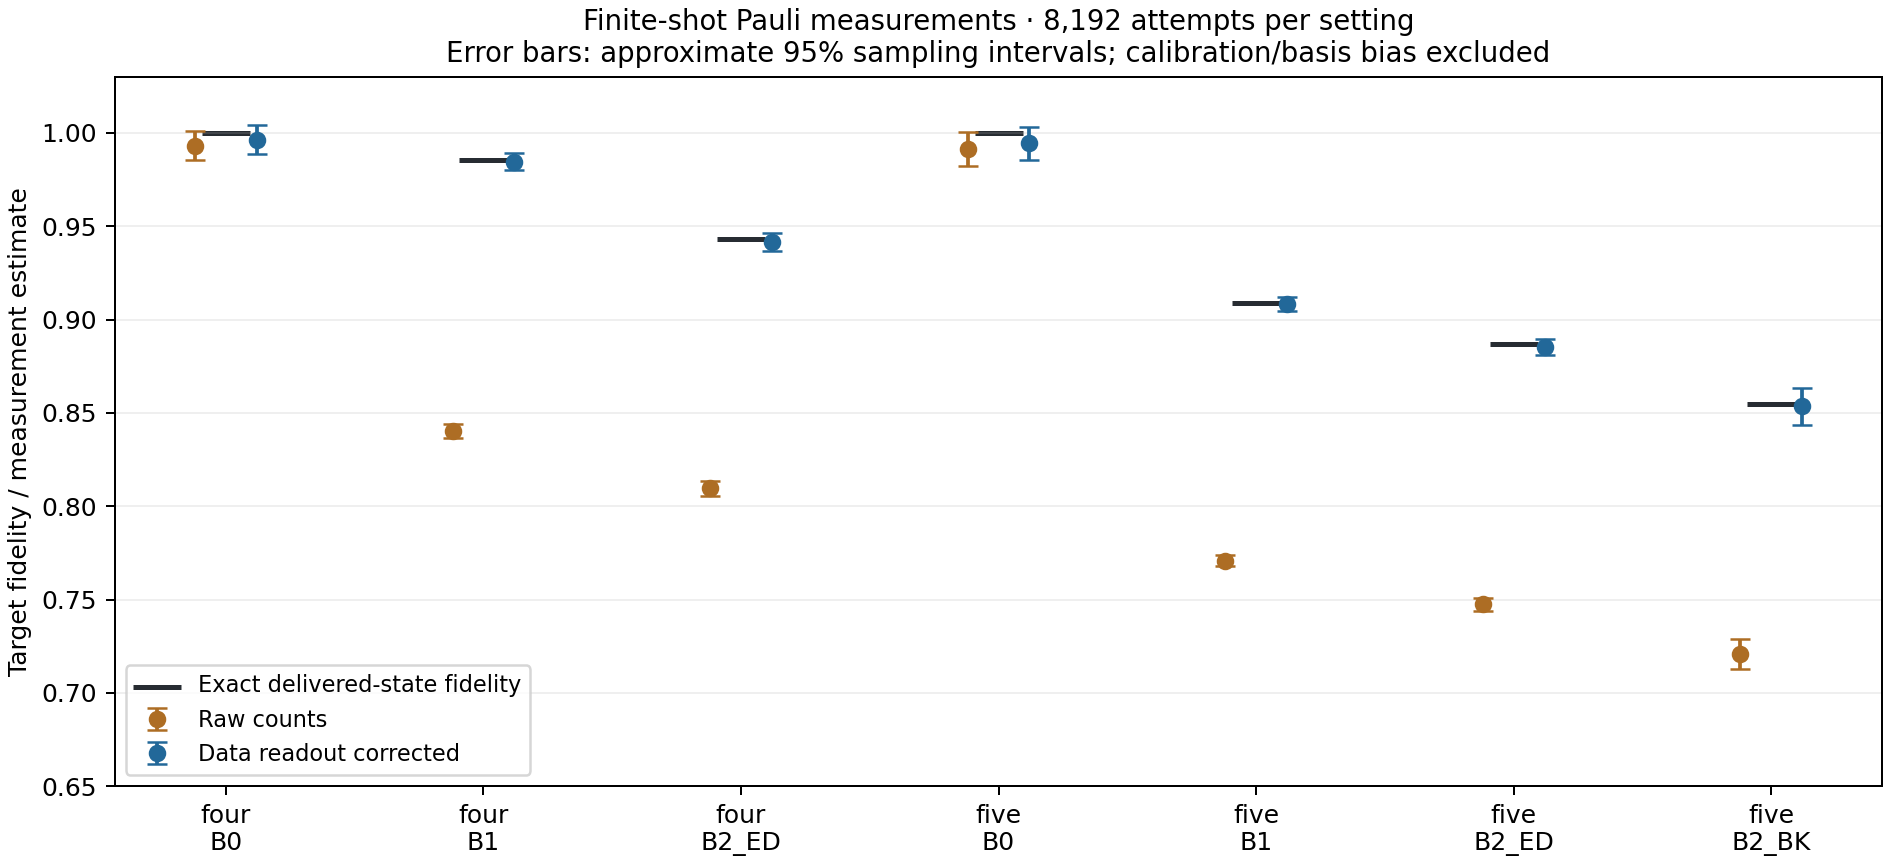

Total attempted quality-measurement shots: 1966080


In [10]:
display(Markdown(quality_table(quality)))
display(Image(filename=str(OUTPUT / 'finite_shot_fidelity.png')))
print('Total attempted quality-measurement shots:', quality['total_quality_measurement_shots'])

### Sampling uncertainty versus measurement bias

For data assignment A[true, recorded], the corrected parity weights solve
`A @ w = [1, -1]`. Products of single-qubit weights give each Pauli-string score.
For symmetric assignment error e, this divides parity by `(1 - 2e)` on each
nonidentity factor. This removes data assignment bias under the stated model.

The error bars are approximate 95% statistical intervals from independent
settings. Conservative Hoeffding/union-bound intervals are also saved. Neither
interval includes calibration uncertainty or basis-rotation/delay bias. The
assignment matrices are treated as exact in this simulation; a hardware
measurement would need calibration and its uncertainty. Estimates and intervals
are left unclipped, so a statistical fluctuation can exceed one.

The simulator-only infinite-shot measurement score below separates residual
measurement bias from finite-shot fluctuations. It is not used to compute the
estimate. The remaining difference from the exact delivered-state fidelity is
due to the noisy analysis rotations and waits.

In [11]:
table = ['| Protocol | Exact delivered-state fidelity | Infinite-shot raw score | Infinite-shot data-readout-corrected score | Remaining corrected bias |',
         '|---|---:|---:|---:|---:|']
for row in quality['rows']:
    r = row['finite_shot']
    raw = r['raw']['infinite_shot_measurement_score_diagnostic']
    corrected = r['data_readout_mitigated']['infinite_shot_measurement_score_diagnostic']
    bias = corrected - row['exact_preparation_fidelity']
    table.append(f"| {row['code']}/{row['strategy']} | {row['exact_preparation_fidelity']:.6f} | {raw:.6f} | {corrected:.6f} | {bias:+.6f} |")
display(Markdown('\n'.join(table)))

| Protocol | Exact delivered-state fidelity | Infinite-shot raw score | Infinite-shot data-readout-corrected score | Remaining corrected bias |
|---|---:|---:|---:|---:|
| four/B0 | 0.999792 | 0.996602 | 0.999774 | -0.000018 |
| four/B1 | 0.985589 | 0.840401 | 0.984940 | -0.000649 |
| four/B2_ED | 0.943088 | 0.810400 | 0.942383 | -0.000705 |
| five/B0 | 0.999784 | 0.996603 | 0.999775 | -0.000009 |
| five/B1 | 0.908950 | 0.770542 | 0.908027 | -0.000923 |
| five/B2_ED | 0.886818 | 0.747860 | 0.885548 | -0.001270 |
| five/B2_BK | 0.854524 | 0.720857 | 0.853304 | -0.001221 |

### Reconstruct the estimate using counts alone

This cell recomputes both four-qubit B2_ED estimates using only raw counts,
Pauli coefficients, and assignment matrices. It does not read an output density
matrix or simulator expectation value. QPY files in `quality_circuits` store
the measurement circuits without any simulator state-save instructions.

In [12]:
from logical_magic.noisy_fidelity import accepted_score, parity_weights

measured = next(r for r in quality['rows'] if r['code'] == 'four' and r['strategy'] == 'B2_ED')
sample = measured['finite_shot']
assignment = [np.asarray(a) for a in sample['data_assignment_matrices']]
for name, matrices in [('raw', None), ('data_readout_mitigated', assignment)]:
    estimate = sample['identity_coefficient']
    variance = 0.0
    for term in sample['terms']:
        weights = parity_weights(term['pauli'], matrices)
        score = accepted_score(term['counts'], n_syndrome=3, weights=weights)
        estimate += term['coefficient'] * score['expectation']
        variance += term['coefficient']**2 * score['variance_of_mean']
    assert np.isclose(estimate, sample[name]['fidelity_estimate'])
    print(f'{name}: {estimate:.6f} ± {1.96*np.sqrt(variance):.6f} (approx. 95% statistical interval)')
print('Accepted shots across settings:', sample['total_accepted_shots'])
print('First setting:', sample['terms'][0]['pauli'])
print('Its raw joint data/syndrome counts:', sample['terms'][0]['counts'])

raw: 0.809648 ± 0.004028 (approx. 95% statistical interval)
data_readout_mitigated: 0.941372 ± 0.004828 (approx. 95% statistical interval)
Accepted shots across settings: 170549
First setting: IIXX
Its raw joint data/syndrome counts: {'1110 101': 1, '1101 101': 1, '1111 110': 1, '1010 011': 4, '0101 100': 1, '1010 101': 1, '0101 110': 1, '1001 000': 31, '1000 111': 3, '1001 101': 2, '1000 010': 8, '0110 101': 2, '1100 011': 7, '0000 101': 2, '1011 111': 4, '1001 011': 2, '0010 100': 3, '1000 110': 4, '1010 010': 4, '1001 100': 3, '0100 101': 15, '0000 011': 5, '1011 001': 2, '1001 110': 1, '0011 001': 31, '1110 011': 12, '1111 010': 32, '0101 011': 1, '1110 001': 15, '0000 100': 11, '1111 001': 37, '1111 000': 1373, '0101 001': 2, '1010 110': 3, '1011 110': 2, '0101 000': 37, '1100 101': 1, '1101 011': 7, '0110 010': 3, '0100 001': 5, '1100 001': 25, '0010 011': 15, '1001 001': 3, '0110 001': 2, '0010 001': 15, '0101 010': 4, '0011 100': 6, '0001 010': 15, '0100 110': 4, '1111 011': 9,

## Scope and saved artifacts

This is a first noisy comparison of the existing bare circuits on one fixed
patch. It does not establish fault tolerance, optimal placement, or a hardware
advantage. B0 is a physical single-qubit output; encoded rows have different
resource costs and delivery times. B2_BK consumes five magic inputs. The model
omits drift, crosstalk, leakage, correlations, and downstream control latency.

Results are in `results/noisy_aachen`: a Markdown report, JSON metadata and raw
counts, accepted density matrices, a PNG/PDF comparison, exact QPY/text circuits,
and copied calibration files. `readout_and_fidelity.json` / `.md` add the
readout-only ablation, finite-shot measurement results, raw counts, statistical
intervals, and systematic-bias diagnostics. No IBM job is submitted and no
credentials are used.

References: [FakeAachen](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider-fake-aachen),
[Aer NoiseModel](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html),
[RelaxationNoisePass](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.RelaxationNoisePass.html).